In [5]:
import pandas as pd

df = pd.read_csv("datasets/student_scores.csv")

print(df.shape)
print(df.head())

(25, 2)
   Hours  Scores
0    2.5      21
1    5.1      47
2    3.2      27
3    8.5      75
4    3.5      30


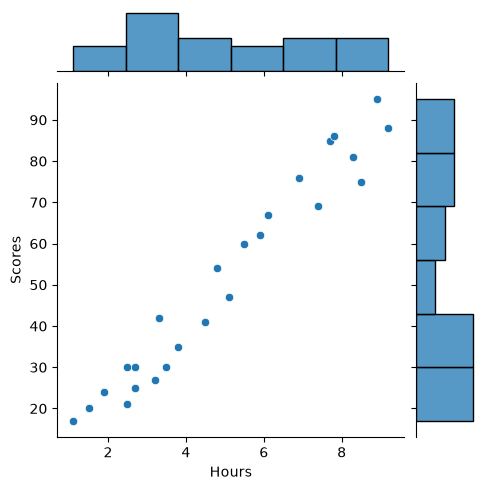

In [6]:
import seaborn as sns
import matplotlib.pyplot as plt


sns.jointplot(data=df, x="Hours", y="Scores", height=5)
plt.show()

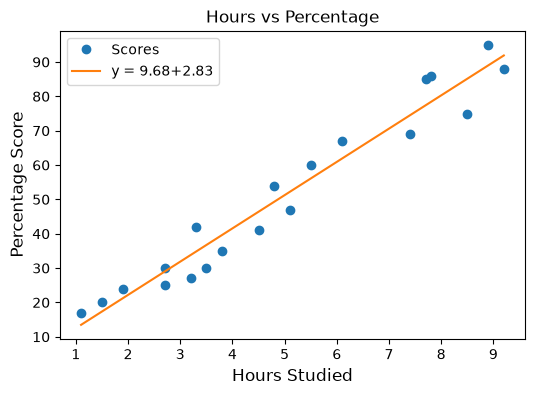

In [7]:
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression


X = df.iloc[:, :-1].values
y = df.iloc[:, 1].values

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

regressor = LinearRegression()

regressor.fit(X_train, y_train)

X_points = np.linspace(min(X_train), max(X_train), 100)
y_pred = regressor.predict(X_points)

plt.figure(figsize=(6, 4))
plt.plot(X_train, y_train, "o", label="Scores")
plt.plot(
    X_points,
    y_pred,
    label="y = %.2f+%.2f" % (regressor.coef_[0], regressor.intercept_),
)
plt.title("Hours vs Percentage", size=12)
plt.xlabel("Hours Studied", size=12)
plt.ylabel("Percentage Score", size=12)
plt.legend()
plt.show()

In [8]:
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score


y_pred = regressor.predict(X_test)

mse = mean_squared_error(y_test, y_pred)

print("Mean squared error: ", mse)
print("Root mean squared error: ", np.sqrt(mse))
print("Mean absolute error: ", mean_absolute_error(y_test, y_pred))
print("R2 score", r2_score(y_test, y_pred))

Mean squared error:  18.943211722315272
Root mean squared error:  4.352380006653288
Mean absolute error:  3.9207511902099244
R2 score 0.9678055545167994
